<a href="https://colab.research.google.com/github/PB-Prakriti/Introduction-to-AI/blob/main/BFS_%26_DFS_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install networkx matplotlib

BFS Traversal: A -> B -> C -> D -> E -> F
DFS Traversal: A -> B -> D -> E -> C -> F


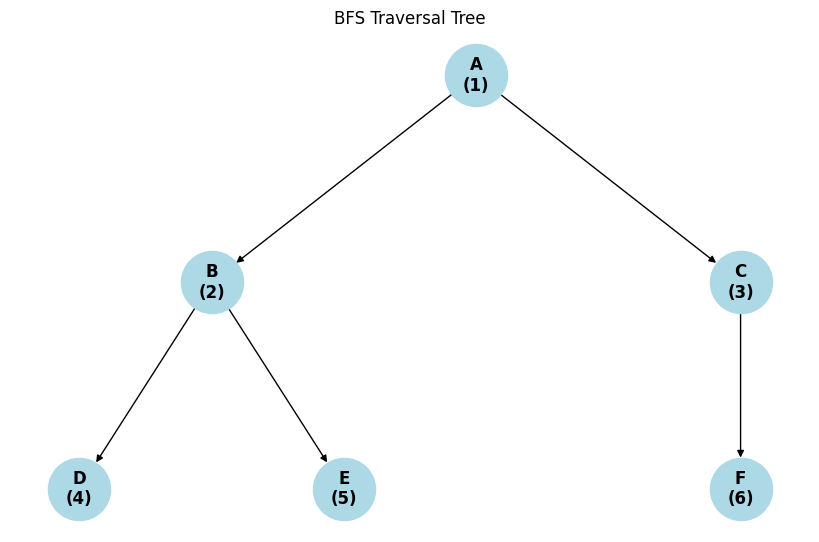

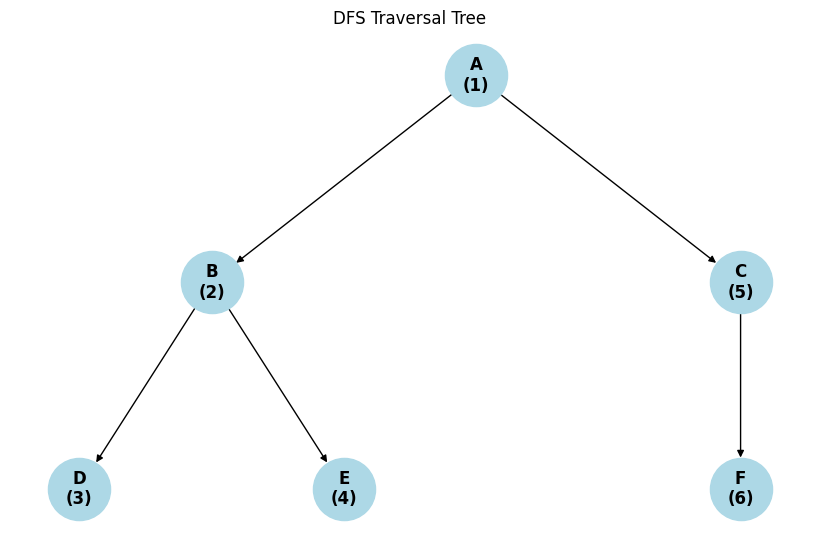

In [ ]:
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

# 1. Store the graph using an adjacency list
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': [],
    'F': []
}

# 2. BFS Traversal
def bfs(graph, start):
    visited = set()
    queue = deque([start])
    traversal = []

    while queue:
        node = queue.popleft()

        if node not in visited:
            visited.add(node)
            traversal.append(node)

            for neighbour in graph[node]:
                if neighbour not in visited:
                    queue.append(neighbour)

    return traversal


# 3. DFS Traversal
def dfs(graph, start):
    visited = set()
    traversal = []

    def dfs_recursive(node):
        visited.add(node)
        traversal.append(node)

        for neighbour in graph[node]:
            if neighbour not in visited:
                dfs_recursive(neighbour)

    dfs_recursive(start)
    return traversal


# Perform traversals
bfs_order = bfs(graph, 'A')
dfs_order = dfs(graph, 'A')

# 4. Print traversal orders
print("BFS Traversal:", " -> ".join(bfs_order))
print("DFS Traversal:", " -> ".join(dfs_order))


# Function to draw traversal tree
def draw_tree(order, title):
    G = nx.DiGraph()

    # Add nodes in traversal order
    for i, node in enumerate(order):
        G.add_node(node, order=i + 1)

    # Add edges according to the original tree
    for parent in graph:
        for child in graph[parent]:
            if parent in order and child in order:
                G.add_edge(parent, child)

    # Tree positions
    pos = {
        'A': (0, 2),
        'B': (-1, 1),
        'C': (1, 1),
        'D': (-1.5, 0),
        'E': (-0.5, 0),
        'F': (1, 0)
    }

    # Labels showing visit order
    labels = {
        node: f"{node}\n({order.index(node) + 1})"
        for node in order
    }

    plt.figure(figsize=(8, 5))
    nx.draw(
        G,
        pos,
        with_labels=True,
        labels=labels,
        node_size=2000,
        node_color='lightblue',
        font_size=12,
        font_weight='bold',
        arrows=True
    )

    plt.title(title)
    plt.axis('off')
    plt.show()


# Draw BFS tree
draw_tree(bfs_order, "BFS Traversal Tree")

# Draw DFS tree
draw_tree(dfs_order, "DFS Traversal Tree")